# A $650 Light-Scattering Flow Cell: Gravity Flow, Pulses, Mie Heights, Budget

**Colin Casey, 2026.** Bench plan for 10/26–12/18/2026. Library: `dgs/scattering_microfluidics.py` (tests: `tests/test_scattering_microfluidics.py`). Related: `dgs/microfluidics.py`, `notebooks/laser_safety.ipynb`, the `scarlett-particle-tagging` sub-project.

## In plain words

A laser sheet crosses a thin glass capillary. Water carrying plastic beads flows through it, pushed only by gravity. Each bead that passes makes a short **flash** of scattered light. A photodiode and amplifier turn the flash into a **voltage pulse**, and a $7 Raspberry Pi Pico digitizes it. Bigger beads scatter more, but **not smoothly**: Mie resonances make the pulse height wiggle with size, so you calibrate with beads of known size. This is a minimal flow cytometer, a slow relative of Jalali's STEAM imaging flow cytometer.

```
 reservoir (height h)                       photodiode (forward, 2-15 deg)
      |                                          ^
      | tubing          laser --> [cyl. lens] --> ====|capillary|==== --> beam block
      +---------------> flow  ->  beads o  o   o      |
                                              side photodiode (75-105 deg)
            Pico ADC  <-- transimpedance amp <-- photocurrent
```

| § | Question | Closed form |
|---|---|---|
| 1 | How fast does it flow with no pump? | $Q=\rho gh/R$, $R=8\mu L/\pi r^4$, $\tau=RA/\rho g$ |
| 2 | How long is each pulse, and how dilute must the beads be? | FWHM $=w\sqrt{2\ln2}/v$; Poisson coincidences |
| 3 | How big is each pulse vs bead size? | Mie theory (Bohren-Huffman), validated 5 ways |
| 4 | Which gains, bandwidth, laser power? What does the scope screen show? | $V=I_0\sigma R_\lambda R_f$, TIA bandwidth |
| 5 | Does it fit $650? | parts list with tax, shipping, reserve |
| 6 | What to measure by 12/18 | bench checklist |

Kernel: **py312**.

In [1]:
import numpy as np
import sympy as sp
sp.init_printing()
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Math
from dgs import scattering_microfluidics as s
OI = dict(orange='#E69F00', sky='#56B4E9', green='#009E73', yellow='#F0E442', blue='#0072B2', red='#D55E00', purple='#CC79A7', black='#000000')
plt.rcParams.update({'figure.dpi': 110, 'axes.grid': True, 'grid.alpha': 0.3})

# ---- design point (edit these) ----
r_cap, L_cap = 0.25e-3, 0.10        # capillary: 0.5 mm ID, 10 cm
r_tub, L_tub = 0.40e-3, 0.30        # tubing: 0.8 mm ID, 30 cm
h0 = 0.10                           # reservoir head (m)
A_res = np.pi * 0.0075**2           # 15 mm ID syringe barrel as reservoir
lam, P_laser = 532e-9, 1e-3         # 1 mW class-2 module
w_flow, w_cross = 25e-6, 300e-6     # light sheet: thin along flow, wide across channel
resp = 0.30                         # A/W, BPW34 near 532 nm (datasheet estimate)
fs, bits, v_ref = 500e3, 12, 3.3    # Pico ADC
beads = [1e-6, 3e-6, 10e-6]

## 1. Gravity flow (SymPy, then numbers)

Poiseuille: $v(r)=\frac{\Delta P}{4\mu L}(R^2-r^2)$. Integrating over the cross-section gives $Q$. A reservoir of area $A$ loses height as it drains: $A\,\dot h=-Q=-\rho g h/R$.

In [2]:
r, R, mu, L, dP, rho, g, A, h0s, t = sp.symbols('r R mu L Delta_P rho g A h_0 t', positive=True)
v = dP/(4*mu*L)*(R**2 - r**2)
Q = sp.integrate(2*sp.pi*r*v, (r, 0, R))
display(Math(r'Q = \int_0^R 2\pi r\,v(r)\,dr = ' + sp.latex(sp.simplify(Q)) + r'\;\Rightarrow\; R_\text{hyd} = ' + sp.latex(sp.simplify(dP/Q))))
display(Math(r'\bar v = Q/\pi R^2 = ' + sp.latex(sp.simplify(Q/(sp.pi*R**2))) + r',\quad v(0) = ' + sp.latex(v.subs(r, 0)) + r' = 2\bar v'))
hf = sp.Function('h'); Rh = sp.symbols('R_h', positive=True)
sol = sp.dsolve(sp.Eq(A*hf(t).diff(t), -rho*g*hf(t)/Rh), hf(t), ics={hf(0): h0s})
display(Math(r'A\dot h = -\rho g h/R_h \;\Rightarrow\; ' + sp.latex(sol) + r',\quad \tau = R_hA/\rho g'))

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

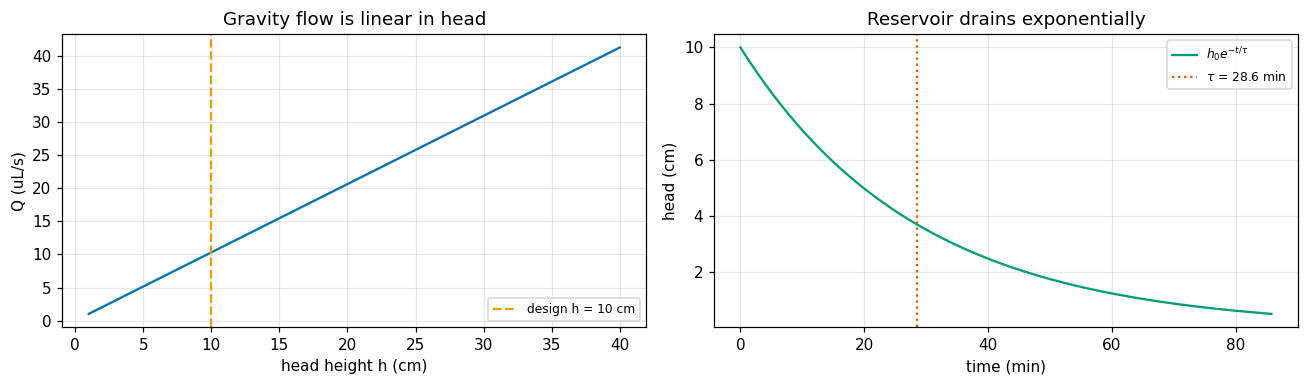

Figure 1. Left: flow rate against reservoir height through the capillary + tubing (solid blue); the dashed orange line marks the 10 cm design point, Q = 10.3 uL/s. Right: the head (and so the flow) decays exponentially as a 15 mm barrel drains (solid green); the dotted red line is one time constant, 28.6 min. Top up the reservoir or use a wide one (larger A, longer tau) for steady flow during a run.


,quantity,value,unit
0,capillary resistance,6.518986e+10,Pa s/m^3
1,tubing resistance,2.984155e+10,Pa s/m^3
2,flow rate Q,1.030226e+01,uL/s
3,mean speed in capillary,5.246896e-02,m/s
4,centerline speed (2x mean),1.049379e-01,m/s
5,Reynolds number,2.618201e+01,-
6,drain time constant tau,2.858833e+01,min
7,volume through in 10 min,6.181354e+00,mL (initial rate)


In [3]:
R_tot = s.tube_resistance(L_cap, r_cap) + s.tube_resistance(L_tub, r_tub)
Q0 = s.gravity_flow(h0, R_tot)
vbar = s.mean_velocity(Q0, r_cap)
tau = s.drain_time_constant(R_tot, A_res)
design = pd.DataFrame([
    ('capillary resistance', s.tube_resistance(L_cap, r_cap), 'Pa s/m^3'),
    ('tubing resistance', s.tube_resistance(L_tub, r_tub), 'Pa s/m^3'),
    ('flow rate Q', Q0*1e9, 'uL/s'),
    ('mean speed in capillary', vbar, 'm/s'),
    ('centerline speed (2x mean)', 2*vbar, 'm/s'),
    ('Reynolds number', s.channel_reynolds(Q0, r_cap), '-'),
    ('drain time constant tau', tau/60, 'min'),
    ('volume through in 10 min', Q0*1e9*600/1e3, 'mL (initial rate)'),
], columns=['quantity', 'value', 'unit'])
hs = np.linspace(0.01, 0.4, 100)
tt = np.linspace(0, 3*tau, 200)
fig, ax = plt.subplots(1, 2, figsize=(12, 3.6))
ax[0].plot(hs*100, s.gravity_flow(hs, R_tot)*1e9, '-', color=OI['blue'])
ax[0].axvline(h0*100, color=OI['orange'], ls='--', label=f'design h = {h0*100:.0f} cm')
ax[0].set(xlabel='head height h (cm)', ylabel='Q (uL/s)', title='Gravity flow is linear in head'); ax[0].legend(fontsize=8)
ax[1].plot(tt/60, s.head_vs_time(h0, tt, tau)*100, '-', color=OI['green'], label='$h_0 e^{-t/\\tau}$')
ax[1].axvline(tau/60, color=OI['red'], ls=':', label=f'$\\tau$ = {tau/60:.1f} min')
ax[1].set(xlabel='time (min)', ylabel='head (cm)', title='Reservoir drains exponentially'); ax[1].legend(fontsize=8)
plt.tight_layout(); plt.show()
print('Figure 1. Left: flow rate against reservoir height through the capillary + tubing (solid blue); the dashed orange line '
      f'marks the 10 cm design point, Q = {Q0*1e9:.1f} uL/s. Right: the head (and so the flow) decays exponentially as a 15 mm '
      f'barrel drains (solid green); the dotted red line is one time constant, {tau/60:.1f} min. Top up the reservoir or use a '
      'wide one (larger A, longer tau) for steady flow during a run.')
design

## 2. Pulse timing and bead dilution

The sheet is a Gaussian, $I\propto e^{-2z^2/w^2}$, along the flow. A bead moving at $v$ gives a pulse of FWHM $w\sqrt{2\ln2}/v$. With no sheath flow (hydrodynamic focusing), beads cross at every radius, so speeds range from about 0 to $2\bar v$ and the pulse widths spread. Pulses should rarely overlap: with Poisson arrivals at rate $cQ$, the chance of a second bead inside a window $\Delta t$ sets the maximum concentration.

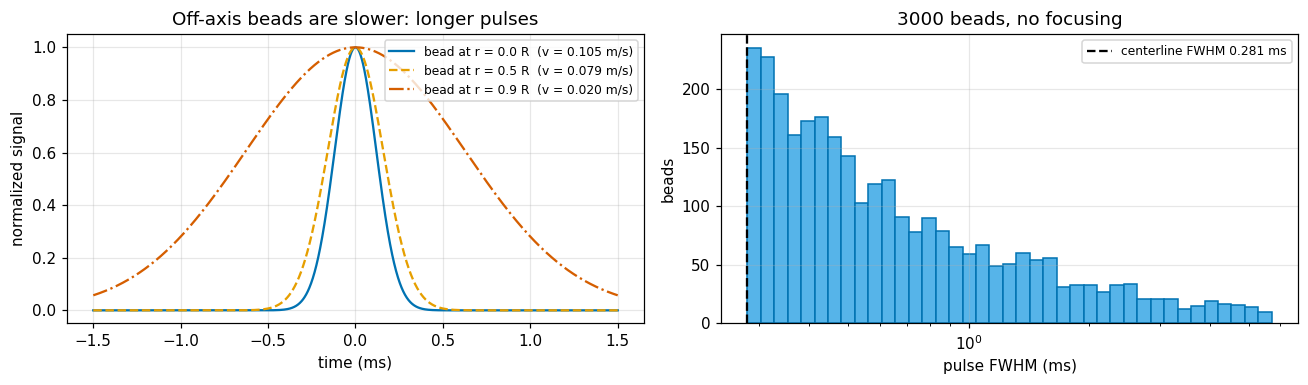

Figure 2. Left: normalized pulses for a bead on the axis (solid blue), at half radius (dashed orange) and near the wall (dash-dot red); slower beads give longer pulses. Right: histogram of pulse widths for 3000 beads spread uniformly over the cross-section (log axis); the dashed black line is the centerline (shortest) width.
centerline FWHM = 0.281 ms -> 140 ADC samples at 500 kS/s; median FWHM 0.531 ms
for <1% coincidences in a 0.95 ms window: concentration <= 2044 beads/mL -> event rate <= 21 beads/s. Dilute the stock bead suspension to about this level.


In [4]:
vc = 2*vbar
fwhm_c = s.pulse_fwhm(w_flow, vc)
widths = s.transit_width_samples(3000, r_cap, vbar, w_flow)
win = 4*w_flow/vc
c_max = s.max_concentration(Q0, win, 0.01)
fig, ax = plt.subplots(1, 2, figsize=(12, 3.6))
tp = np.linspace(-1.5e-3, 1.5e-3, 3001)
for frac, c, ls in [(0.0, OI['blue'], '-'), (0.5, OI['orange'], '--'), (0.9, OI['red'], '-.')]:
    vv = s.poiseuille_velocity(frac*r_cap, r_cap, vbar)
    ax[0].plot(tp*1e3, s.pulse_shape(tp, vv, w_flow), ls, color=c, label=f'bead at r = {frac:.1f} R  (v = {vv:.3f} m/s)')
ax[0].set(xlabel='time (ms)', ylabel='normalized signal', title='Off-axis beads are slower: longer pulses'); ax[0].legend(fontsize=8)
ax[1].hist(widths*1e3, bins=np.logspace(np.log10(widths.min()*1e3), np.log10(np.percentile(widths, 99)*1e3), 40), color=OI['sky'], edgecolor=OI['blue'])
ax[1].axvline(fwhm_c*1e3, color=OI['black'], ls='--', label=f'centerline FWHM {fwhm_c*1e3:.3f} ms')
ax[1].set(xscale='log', xlabel='pulse FWHM (ms)', ylabel='beads', title='3000 beads, no focusing'); ax[1].legend(fontsize=8)
plt.tight_layout(); plt.show()
print('Figure 2. Left: normalized pulses for a bead on the axis (solid blue), at half radius (dashed orange) and near the wall '
      '(dash-dot red); slower beads give longer pulses. Right: histogram of pulse widths for 3000 beads spread uniformly over '
      'the cross-section (log axis); the dashed black line is the centerline (shortest) width.')
print(f'centerline FWHM = {fwhm_c*1e3:.3f} ms -> {fwhm_c*fs:.0f} ADC samples at {fs/1e3:.0f} kS/s; median FWHM {np.median(widths)*1e3:.3f} ms')
print(f'for <1% coincidences in a {win*1e3:.2f} ms window: concentration <= {c_max:.0f} beads/mL '
      f'-> event rate <= {c_max*Q0*1e6:.0f} beads/s. Dilute the stock bead suspension to about this level.')

## 3. Mie pulse heights vs bead size

Polystyrene ($n\approx1.59$) in water ($n=1.333$): $m\approx1.19$, $x=\pi d\,n_\text{med}/\lambda$. The light collected into an angular window is
$$\sigma_\text{col}=\frac{2\pi f_\phi}{k^2}\int_{\theta_1}^{\theta_2}\tfrac12\big(|S_1|^2+|S_2|^2\big)\sin\theta\,d\theta,$$
with Mie amplitudes $S_{1,2}$ from the Bohren-Huffman series. First, five checks that the Mie code is right:

In [5]:
import pathlib, sys
m_ps = s.N_POLYSTYRENE/s.N_WATER
x3 = s.size_parameter(3e-6, lam)
csca3 = s.mie_efficiencies(m_ps, x3)[1]*np.pi*(1.5e-6)**2
checks = [('Bohren-Huffman example m=1.55, x=5.213: Q_sca', s.mie_efficiencies(1.55, 5.213)[1], 3.105, 'book value ~3.105 (recalled)'),
          ('Rayleigh limit m=1.2, x=0.05: Q_sca', s.mie_efficiencies(1.2, 0.05)[1], s.rayleigh_qsca(1.2, 0.05), '(8/3)x^4|(m^2-1)/(m^2+2)|^2'),
          ('anomalous diffraction m=1.02, x=200: Q_ext', s.mie_efficiencies(1.02, 200)[0],
           2 - 4/8*np.sin(8.0) + 4/64*(1 - np.cos(8.0)), 'van de Hulst (approximate)'),
          ('3 um PS: angular integral 0..pi / C_sca', s.collected_cross_section(3e-6, lam, 0, np.pi, n_theta=4000), csca3, 'energy bookkeeping')]
src = pathlib.Path.cwd().parent / 'scarlett-particle-tagging' / 'src'
if src.exists():
    sys.path.insert(0, str(src))
    from scarlett import physics as P
    checks.append(('independent code (scarlett) m=1.19, x=17.7: Q_sca', s.mie_efficiencies(1.19, 17.7)[1], P.mie_efficiencies(1.19, 17.7)['qsca'], 'scarlett-particle-tagging'))
mie_ok = pd.DataFrame(checks, columns=['check', 'this module', 'reference', 'source'])
mie_ok['rel_diff'] = (mie_ok['this module']/mie_ok['reference'] - 1).abs()
mie_ok

,check,this module,reference,source,rel_diff
0,"Bohren-Huffman example m=1.55, x=5.213: Q_sca",3.104996e+00,3.105000e+00,book value ~3.105 (recalled),1.315594e-06
1,"Rayleigh limit m=1.2, x=0.05: Q_sca",2.725367e-07,2.726699e-07,(8/3)x^4|(m^2-1)/(m^2+2)|^2,4.885888e-04
2,"anomalous diffraction m=1.02, x=200: Q_ext",1.604090e+00,1.576915e+00,van de Hulst (approximate),1.723351e-02
3,3 um PS: angular integral 0..pi / C_sca,1.541037e-11,1.541049e-11,energy bookkeeping,8.055091e-06
4,"independent code (scarlett) m=1.19, x=17.7: Q_sca",1.938709e+00,1.938709e+00,scarlett-particle-tagging,1.887379e-15


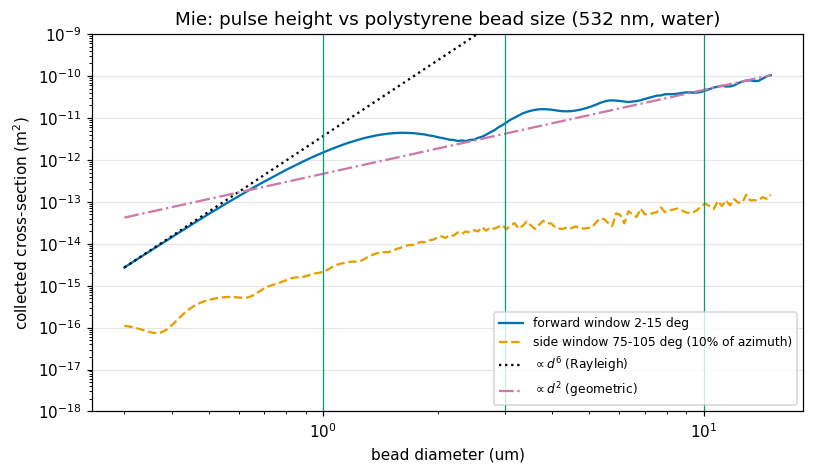

Figure 3. Collected scattering cross-section (proportional to pulse height) against bead diameter on log-log axes. Solid blue: forward window; dashed orange: side window. Dotted black and dash-dot purple are the small-particle (d^6) and large-particle (d^2) trends. Thin green lines mark the 1, 3 and 10 um calibration beads. Neither curve is monotonic: the forward signal peaks near 1.6 um and dips near 2.3 um, and the side signal ripples from ~2 um up (Mie resonances). So one pulse height can match more than one size, which is why you need calibration beads and two channels. It is a sizing ambiguity much like the phase-retrieval ambiguities elsewhere in this repo.
forward local max at 1.60 um, local min at 2.37 um (height ratio 1.58)


In [6]:
ds = np.logspace(np.log10(0.3e-6), np.log10(15e-6), 160)
fwd = np.array([s.collected_cross_section(d, lam, np.deg2rad(2), np.deg2rad(15)) for d in ds])
side = np.array([s.collected_cross_section(d, lam, np.deg2rad(75), np.deg2rad(105), 0.1) for d in ds])
fig, ax = plt.subplots(figsize=(7.5, 4.4))
ax.loglog(ds*1e6, fwd, '-', color=OI['blue'], label='forward window 2-15 deg')
ax.loglog(ds*1e6, side, '--', color=OI['orange'], label='side window 75-105 deg (10% of azimuth)')
ax.loglog(ds*1e6, fwd[0]*(ds/ds[0])**6, ':', color=OI['black'], label='$\\propto d^6$ (Rayleigh)')
ax.loglog(ds*1e6, fwd[-1]*(ds/ds[-1])**2, '-.', color=OI['purple'], label='$\\propto d^2$ (geometric)')
for d in beads:
    ax.axvline(d*1e6, color=OI['green'], lw=0.8)
ax.set(xlabel='bead diameter (um)', ylabel='collected cross-section (m$^2$)', ylim=(1e-18, 1e-9),
       title='Mie: pulse height vs polystyrene bead size (532 nm, water)'); ax.legend(fontsize=8)
plt.tight_layout(); plt.show()
print('Figure 3. Collected scattering cross-section (proportional to pulse height) against bead diameter on log-log axes. '
      'Solid blue: forward window; dashed orange: side window. Dotted black and dash-dot purple are the small-particle '
      '(d^6) and large-particle (d^2) trends. Thin green lines mark the 1, 3 and 10 um calibration beads. Neither curve is '
      'monotonic: the forward signal peaks near 1.6 um and dips near 2.3 um, and the side signal ripples from ~2 um up (Mie '
      'resonances). So one pulse height can match more than one size, which is why you need calibration beads and two '
      'channels. It is a sizing ambiguity much like the phase-retrieval ambiguities elsewhere in this repo.')
fwd_pk = ds[(ds > 1e-6) & (ds < 2e-6)][np.argmax(fwd[(ds > 1e-6) & (ds < 2e-6)])]
fwd_dip = ds[(ds > 2e-6) & (ds < 3e-6)][np.argmin(fwd[(ds > 2e-6) & (ds < 3e-6)])]
print(f'forward local max at {fwd_pk*1e6:.2f} um, local min at {fwd_dip*1e6:.2f} um '
      f'(height ratio {np.interp(fwd_pk, ds, fwd)/np.interp(fwd_dip, ds, fwd):.2f})')

## 4. Detector design and the "oscilloscope screen"

Pulse height $V=I_0\,\sigma_\text{col}\,R_\lambda\,R_f$, with sheet peak irradiance $I_0=2P/(\pi w_\text{flow}w_\text{cross})$. Forward light is about 100× stronger than side light, so the two channels need **different feedback resistors** to fit the Pico's 0–3.3 V range. The TIA has to be fast enough for the shortest pulse.

In [7]:
Rf = {'forward': 1e6, 'side': 100e6}
win_ = {'forward': (2, 15, 1.0), 'side': (75, 105, 0.1)}
rows = []
for ch, (a1, a2, fphi) in win_.items():
    for d in beads:
        sig = s.collected_cross_section(d, lam, np.deg2rad(a1), np.deg2rad(a2), fphi)
        V = float(s.pulse_height_volts(sig, P_laser, w_flow, resp, Rf[ch], w_cross))
        rows.append(dict(channel=ch, bead_um=d*1e6, R_f_ohm=Rf[ch], sigma_col_m2=sig, V_peak=V,
                         adc_counts=int(s.adc_counts(V, bits, v_ref)), clipped=V > v_ref))
heights = pd.DataFrame(rows)
need_bw = 0.35/(fwhm_c/2)            # rise ~ half the FWHM
bw = {ch: s.tia_bandwidth(10e6, Rf[ch], 25e-12) for ch in Rf}
print(f'peak irradiance (sheet) = {s.peak_irradiance(P_laser, w_flow, w_cross):.3g} W/m^2 '
      f'(round 25 um spot would be {s.peak_irradiance(P_laser, w_flow):.3g}, 12x higher but misses most beads)')
print(f'needed bandwidth ~ {need_bw/1e3:.1f} kHz; TIA (10 MHz GBW op-amp, 25 pF diode): forward {bw["forward"]/1e3:.0f} kHz, side {bw["side"]/1e3:.0f} kHz')
print(f'at 1 mW, a {beads[1]*1e6:.0f} um bead gives {heights.query("channel==\'forward\' and bead_um==3").V_peak.iloc[0]:.2f} V forward: '
      'no need for a stronger (class 3R/3B) laser.')
heights

peak irradiance (sheet) = 8.49e+04 W/m^2 (round 25 um spot would be 1.02e+06, 12x higher but misses most beads)
needed bandwidth ~ 2.5 kHz; TIA (10 MHz GBW op-amp, 25 pF diode): forward 252 kHz, side 25 kHz
at 1 mW, a 3 um bead gives 0.19 V forward: no need for a stronger (class 3R/3B) laser.


,channel,bead_um,R_f_ohm,sigma_col_m2,V_peak,adc_counts,clipped
0,forward,1.0,1000000.0,1.514710e-12,0.038572,48,False
1,forward,3.0,1000000.0,7.485276e-12,0.190611,237,False
2,forward,10.0,1000000.0,4.385982e-11,1.116881,1386,False
3,side,1.0,100000000.0,2.144212e-15,0.005460,7,False
4,side,3.0,100000000.0,2.502958e-14,0.063737,79,False
5,side,10.0,100000000.0,9.207557e-14,0.234469,291,False


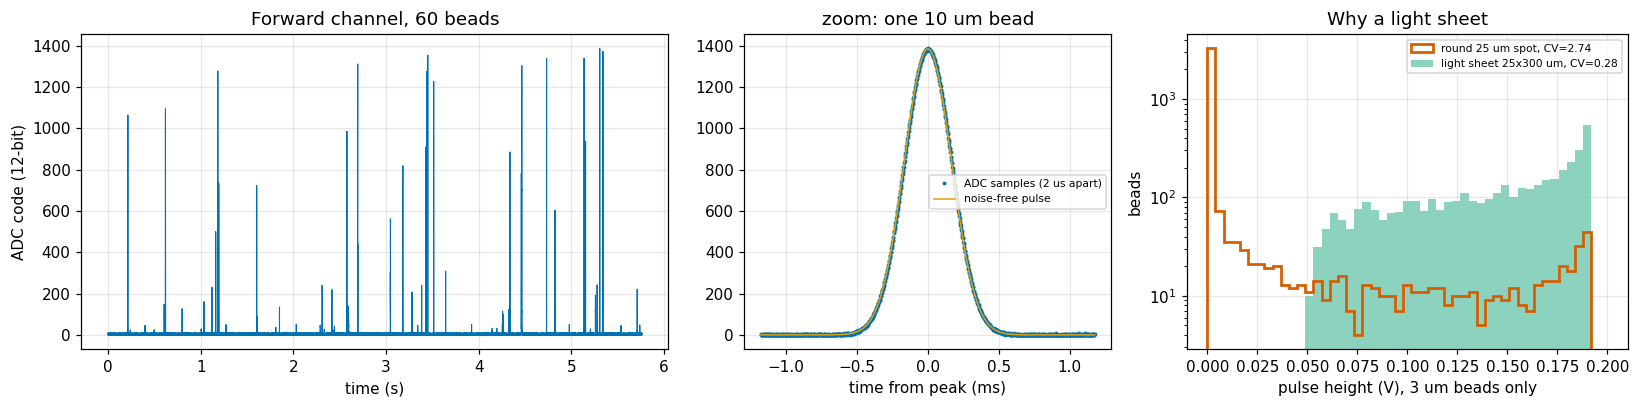

Figure 4. Left: the "oscilloscope screen", a simulated forward-channel record of mixed 1/3/10 um beads in 12-bit ADC codes (2 mV rms noise assumed). Tall spikes are 10 um beads, mid-height 3 um, small 1 um; off-center beads come out weaker. Middle: zoom on the tallest pulse; blue dots are individual ADC samples 2 us apart, the orange line the noise-free pulse. Right: pulse-height histograms for 4000 identical 3 um beads with a round 25 um spot (red outline) vs a 25 x 300 um light sheet (green filled), log count axis. The spot gives a huge spread because most beads miss the focus; the sheet keeps heights within a factor ~4. Its remaining spread comes from beads near the wall, where the 300 um sheet is weaker; a wider sheet or a narrower capillary narrows it further.


In [8]:
hv = {d: float(heights.query('channel=="forward" and bead_um==@d*1e6').V_peak.iloc[0]) for d in beads}
rate = 0.5*c_max*Q0*1e6
ev_sheet = s.simulate_events(60, beads, hv, r_cap, vbar, w_flow, w_cross, rate, seed=2)
t_tr, V_tr, codes = s.adc_trace(ev_sheet, fs, w_flow, bits, v_ref, noise_v=2e-3, seed=5)
many_spot = s.simulate_events(4000, [3e-6], hv, r_cap, vbar, w_flow, w_flow, rate, seed=7)
many_sheet = s.simulate_events(4000, [3e-6], hv, r_cap, vbar, w_flow, w_cross, rate, seed=7)
fig, ax = plt.subplots(1, 3, figsize=(15, 3.8), gridspec_kw=dict(width_ratios=[1.6, 1, 1.2]))
ax[0].plot(t_tr, codes, '-', color=OI['blue'], lw=0.7)
ax[0].set(xlabel='time (s)', ylabel='ADC code (12-bit)', title=f'Forward channel, {len(ev_sheet["t0"])} beads')
i10 = int(np.argmax(ev_sheet['height']))
sl = np.abs(t_tr - ev_sheet['t0'][i10]) < 3*ev_sheet['fwhm'][i10]
ax[1].plot((t_tr[sl] - ev_sheet['t0'][i10])*1e3, codes[sl], '.', ms=3, color=OI['blue'], label='ADC samples (2 us apart)')
ax[1].plot((t_tr[sl] - ev_sheet['t0'][i10])*1e3,
           s.adc_counts(s.pulse_shape(t_tr[sl] - ev_sheet['t0'][i10], ev_sheet['v'][i10], w_flow, ev_sheet['height'][i10]), bits, v_ref),
           '-', color=OI['orange'], lw=1, label='noise-free pulse')
ax[1].set(xlabel='time from peak (ms)', title=f'zoom: one {ev_sheet["d"][i10]*1e6:.0f} um bead'); ax[1].legend(fontsize=7)
cv = lambda a: a.std()/a.mean()
b = np.linspace(0, hv[3e-6]*1.05, 50)
ax[2].hist(many_spot['height'], bins=b, histtype='step', lw=1.8, color=OI['red'], label=f'round 25 um spot, CV={cv(many_spot["height"]):.2f}')
ax[2].hist(many_sheet['height'], bins=b, histtype='stepfilled', alpha=0.45, color=OI['green'], label=f'light sheet 25x300 um, CV={cv(many_sheet["height"]):.2f}')
ax[2].set(yscale='log', xlabel='pulse height (V), 3 um beads only', ylabel='beads', title='Why a light sheet'); ax[2].legend(fontsize=7)
plt.tight_layout(); plt.show()
print('Figure 4. Left: the "oscilloscope screen", a simulated forward-channel record of mixed 1/3/10 um beads in 12-bit ADC '
      'codes (2 mV rms noise assumed). Tall spikes are 10 um beads, mid-height 3 um, small 1 um; off-center beads come out '
      'weaker. Middle: zoom on the tallest pulse; blue dots are individual ADC samples 2 us apart, the orange line the '
      'noise-free pulse. Right: pulse-height histograms for 4000 identical 3 um beads with a round 25 um spot (red outline) vs a '
      '25 x 300 um light sheet (green filled), log count axis. The spot gives a huge spread because most beads miss the '
      'focus; the sheet keeps heights within a factor ~4. Its remaining spread comes from beads near the wall, '
      'where the 300 um sheet is weaker; a wider sheet or a narrower capillary narrows it further.')

## 5. The $650 budget

Prices are **rough estimates written from memory**; check vendors and ask a lab about borrowing beads, capillaries, or a scope first. Sales tax is taken as 8.75% (Sacramento; check your address), plus a shipping allowance.

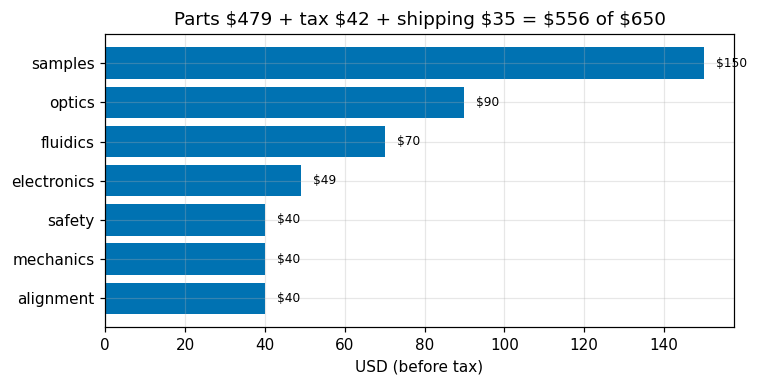

Figure 5. Pre-tax spending by category (blue bars, labeled in dollars). Calibration beads dominate; ask a lab to lend them before buying.
{'subtotal': 479.0, 'tax': 41.91, 'shipping': 35.0, 'total': 555.91, 'reserve': 94.09, 'within_cap': True}


,item,category,qty,unit_usd,line_usd,why
0,"Laser safety glasses, OD4+ at the laser wavele...",safety,1,40,40,required before the laser is ever powered
1,"Laser diode module, <=1 mW class 2 (532 or 650...",optics,1,25,25,1 mW already gives ~0.1-1 V pulses (Sec. 4)
2,Lens kit: cylindrical (light sheet) + plano-co...,optics,1,40,40,25 x 300 um sheet; collect forward/side light
3,ND filter / beam block,optics,1,25,25,block the direct beam
4,"Borosilicate capillaries, ~0.5 mm ID",fluidics,1,40,40,flow cell
5,"Tubing, Luer fittings, syringes, reservoir",fluidics,1,30,30,"gravity-driven flow, no pump"
6,"Polystyrene calibration beads, 2-3 sizes",samples,1,150,150,known sizes to calibrate pulse height
7,BPW34 photodiodes,electronics,5,2,10,detectors (spares)
8,"Op-amps, resistors, capacitors, breadboard",electronics,1,25,25,transimpedance amplifier
9,Raspberry Pi Pico 2,electronics,2,7,14,12-bit ADC + USB logging


In [9]:
parts = pd.DataFrame(s.PARTS)
parts['line_usd'] = parts.qty*parts.unit_usd
summary = s.budget_summary()
by_cat = parts.groupby('category').line_usd.sum().sort_values()
fig, ax = plt.subplots(figsize=(7, 3.6))
ax.barh(by_cat.index, by_cat.values, color=OI['blue'])
for i, v_ in enumerate(by_cat.values):
    ax.text(v_ + 3, i, f'${v_:.0f}', va='center', fontsize=8)
ax.set(xlabel='USD (before tax)', title=f"Parts ${summary['subtotal']:.0f} + tax ${summary['tax']:.0f} + shipping ${summary['shipping']:.0f} = ${summary['total']:.0f} of $650")
plt.tight_layout(); plt.show()
print('Figure 5. Pre-tax spending by category (blue bars, labeled in dollars). Calibration beads dominate; ask a lab to lend them '
      'before buying.')
print(summary)
parts[['item', 'category', 'qty', 'unit_usd', 'line_usd', 'why']]

## 6. Bench plan to 12/18 and what to measure against this notebook

| Week | Do | Compare with |
|---|---|---|
| 10/26 | Talk to a faculty mentor and EH&S (laser rules); borrow what you can; order glasses, laser, Pico | §5 budget |
| 11/2 | Build the TIA + Pico logger; test with an LED, no laser | §4 bandwidth, ADC codes |
| 11/9 | Gravity flow: time 1 mL; mark the reservoir level over time | §1 $Q$, $\tau$ |
| 11/16 | Align the light sheet with the USB microscope; first 3 µm bead pulses | §2 FWHM, §4 heights |
| 11/23 (Thanksgiving) | Run 1, 3, 10 µm beads; histogram the heights | Fig. 3 / Fig. 4 ratios |
| 11/30–12/7 | Calibrate height vs size; one unknown sample (e.g. diluted milk) | §3 ambiguity |
| by 12/18 | Write-up before finals | |

**Validation checklist (model side, all computed above):** Poiseuille integral (SymPy), drain ODE (SymPy), Mie vs 5 references, pulse FWHM formula (tests), the light sheet's height spread, budget under cap.

**References** (from memory; verify before citing)
[1] C. F. Bohren and D. R. Huffman, *Absorption and Scattering of Light by Small Particles*. New York, NY, USA: Wiley, 1983.
[2] H. C. van de Hulst, *Light Scattering by Small Particles*. New York, NY, USA: Wiley, 1957.
[3] H. Bruus, *Theoretical Microfluidics*. Oxford, U.K.: Oxford Univ. Press, 2008.
[4] H. M. Shapiro, *Practical Flow Cytometry*, 4th ed. Hoboken, NJ, USA: Wiley-Liss, 2003.
[5] K. Goda, K. K. Tsia, and B. Jalali, "Serial time-encoded amplified imaging for real-time observation of fast dynamic phenomena," *Nature*, vol. 458, pp. 1145–1149, 2009.

**Limitations.**
- Unpolarized averaging: a laser diode is polarized, so side scatter depends on its orientation.
- The side window is approximated as a θ band times an azimuthal fraction.
- Refraction and lensing at the curved capillary wall are ignored.
- $n_\text{PS}=1.59$ is approximate, and responsivity and noise are assumed values.
- All prices are estimates.